# Parcours : mesurer l'erreur de modèle d'une provision

Ce carnet suit l'article pas à pas (Taylor et McGuire, *Risks* 2023, 11, 185). Il n'a aucune logique propre :
il appelle les modules de `src/` et relit les résultats écrits par `run_all.py`.
Données entièrement fictives. Le fil rouge est recalculé ici (environ une minute) ; le cas à l'échelle
(bootstrap, contrôle de réalisme) est trop long pour un carnet et se relit depuis `results/`.

In [1]:
import os, sys
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebook' else None
sys.path.insert(0, '.')
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 200)
os.makedirs('work', exist_ok=True)

## 1. Le fil rouge : un triangle annuel 10 x 10

In [2]:
from src.fil_rouge import run
r, tab, summ, y, mu, past = run('work', 'results')
pd.read_csv('results/fil_rouge_triangle.csv', index_col=0)

,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10
S1,454.0,1146.0,1120.0,1491.0,1166.0,810.0,586.0,452.0,274.0,180.0
S2,595.0,1217.0,1386.0,1322.0,1139.0,802.0,596.0,486.0,291.0,NaN
S3,508.0,1272.0,1405.0,1354.0,1237.0,1116.0,588.0,573.0,NaN,NaN
S4,498.0,1476.0,1683.0,1659.0,1141.0,1048.0,658.0,NaN,NaN,NaN
S5,663.0,1310.0,1567.0,1841.0,1438.0,1137.0,NaN,NaN,NaN,NaN
S6,873.0,1632.0,1727.0,1908.0,1408.0,NaN,NaN,NaN,NaN,NaN
S7,664.0,1493.0,1829.0,1679.0,NaN,NaN,NaN,NaN,NaN,NaN
S8,657.0,1668.0,2567.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
S9,1072.0,1808.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
S10,1033.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Les briques 1 à 3 : famille de modèles, vraisemblance, a priori
Chaque ligne est un modèle de la famille LASSO (une valeur de la pénalité).

In [3]:
fam = pd.read_csv('results/fil_rouge_famille.csv')
fam.iloc[::20]

,q,lambda_,nb_variables,provision,log_vraisemblance,log_apriori,admis,poids_aposteriori
0,1,341.250316,1.0,50486.006470,-1070.240780,-4.697242e-14,False,0.000000e+00
20,21,133.324449,9.0,48372.973572,-606.048630,-1.142067e+02,True,5.114038e-48
40,41,52.089061,23.0,48799.310852,-406.870803,-2.122090e+02,True,4.454098e-04
60,61,20.350883,29.0,48458.876801,-345.918969,-2.710662e+02,True,3.617680e-03
80,81,7.950968,39.0,47882.026077,-321.271923,-3.289690e+02,True,1.305035e-17
100,101,3.106395,66.0,45429.092102,-309.730314,-4.200700e+02,True,3.659732e-52
120,121,1.213650,70.0,43973.324417,-303.775126,-5.497892e+02,True,6.507182e-106
140,141,0.493423,79.0,44170.744217,-301.408375,-6.583897e+02,True,4.749668e-152
160,161,0.287045,81.0,44267.273315,-301.072123,-6.915102e+02,True,2.745660e-166
180,181,0.166986,84.0,44320.988281,-300.937186,-7.142654e+02,True,4.119134e-176


## 3. Les briques 4 et 5 : portes puis vote bayésien, à la main sur 5 modèles
log a posteriori = log a priori + log vraisemblance ; on retranche le maximum, on prend l'exponentielle, on normalise.

In [4]:
t = pd.read_csv('results/fil_rouge_5_modeles.csv')
t[['modele', 'nb_variables', 'log_apriori', 'log_vraisemblance', 'log_aposteriori', 'ecart_au_max', 'exp_ecart', 'poids', 'provision']].round(4)

,modele,nb_variables,log_apriori,log_vraisemblance,log_aposteriori,ecart_au_max,exp_ecart,poids,provision
0,M44,23,-224.5957,-391.1786,-615.7743,-2.0246,0.1320,0.0493,48485.0698
1,M48,24,-239.3776,-374.6901,-614.0678,-0.3181,0.7275,0.2716,48105.9305
2,M52,24,-251.2601,-362.4895,-613.7497,0.0000,1.0000,0.3734,47881.0023
3,M56,24,-259.7121,-354.4298,-614.1419,-0.3922,0.6755,0.2522,47741.4568
4,M60,29,-267.7363,-347.9574,-615.6937,-1.9441,0.1431,0.0534,48144.8336


In [5]:
# vérification à la main
e = np.exp(t.log_aposteriori - t.log_aposteriori.max())
w = e / e.sum()
m = (w * t.provision).sum()
sd = np.sqrt((w * (t.provision - m) ** 2).sum())
print(f'moyenne pondérée = {m:,.0f} ; écart type = {sd:,.0f} ; CoV = {100 * sd / m:.2f} %')
print(pd.read_csv('results/fil_rouge_resume.csv', index_col=0).round(4))

moyenne pondérée = 47,951 ; écart type = 188 ; CoV = 0.39 %
                             valeur
provision_vraie          39928.4434
s_laplace                    0.0032
phi                          0.0092
Q                          439.0000
n_admis                    436.0000
q_1se                       52.0000
q_minCV                     70.0000
provision_1se_brute      47881.0023
bma_complete_moyenne     47944.2381
bma_complete_cov             0.0040
bma_complete_nb_modeles     23.0000
bma5_moyenne             47950.7843
bma5_ecart_type            188.4021
bma5_cov                     0.0039


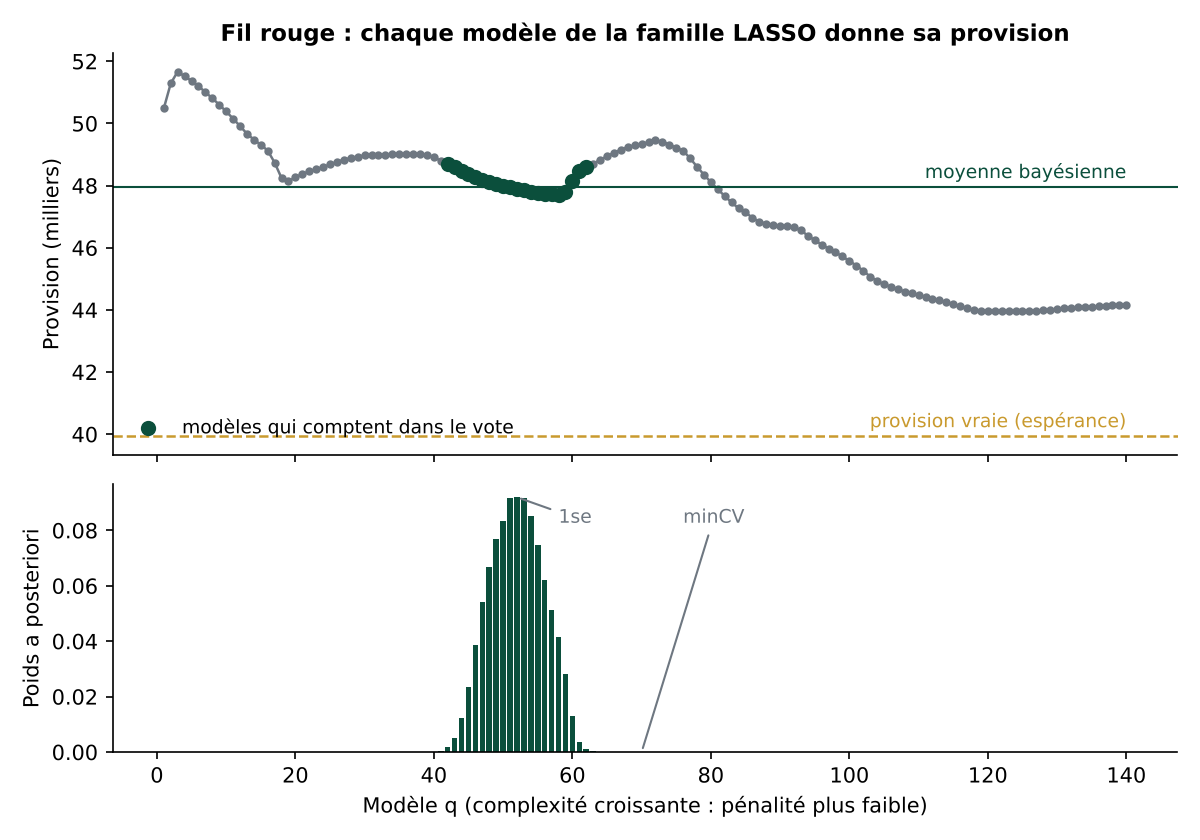

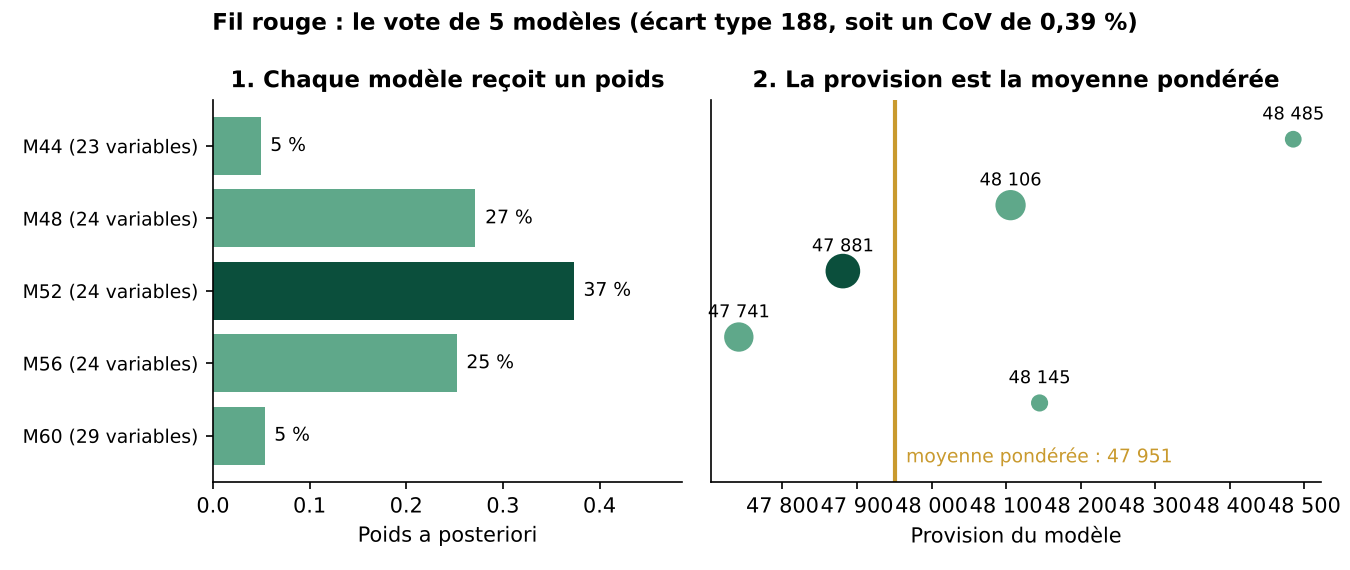

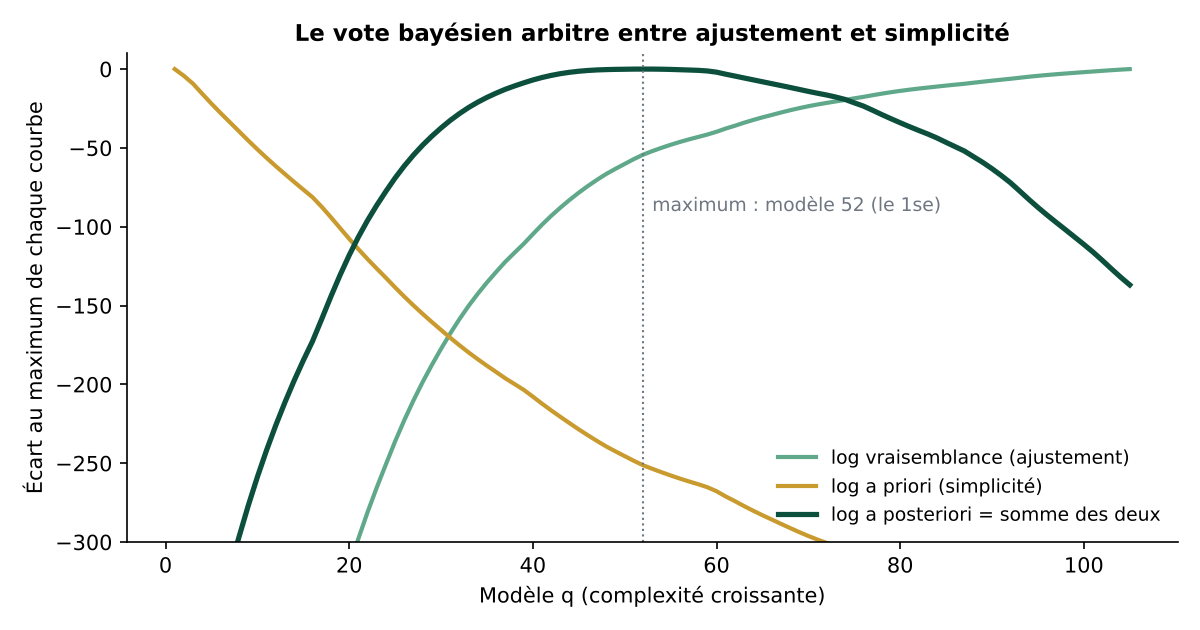

In [6]:
for f in ('fig_fil_rouge_famille', 'fig_fil_rouge_vote', 'fig_fil_rouge_compromis'):
    display(Image(f'results/figures/{f}.png'))

## 4. Cas à l'échelle : jeux 1 et 2 du papier (triangles trimestriels 40 x 40)

In [7]:
pd.read_csv('results/modele_principal.csv').round(4)

,jeu,apriori,s_laplace,provision_vraie,provision_1se_brute,moyenne_aposteriori,imse_cov,nb_modeles_proba_sup_1e4,mode_q,calibrage_atteint
0,1,simple,0.0021,1.887093e+11,1.946894e+11,1.965978e+11,0.0065,13,104,NaN
1,1,1se,0.0024,1.887093e+11,1.946894e+11,1.948359e+11,0.0026,17,110,True
2,1,minCV,0.0030,1.887093e+11,1.946894e+11,1.904586e+11,0.0071,14,122,True
3,1,complexe,0.0038,1.887093e+11,1.946894e+11,1.984441e+11,0.0185,10,126,NaN
4,2,simple,0.0028,2.381041e+11,3.109792e+11,3.051665e+11,0.0076,18,101,NaN
5,2,1se,0.0032,2.381041e+11,3.109792e+11,3.106370e+11,0.0047,21,109,False
6,2,minCV,0.0051,2.381041e+11,3.109792e+11,3.103405e+11,0.0032,14,127,True
7,2,complexe,0.0070,2.381041e+11,3.109792e+11,3.115951e+11,0.0031,12,134,NaN


In [8]:
pd.read_csv('results/bootstrap.csv').round(4)

,jeu,apriori,elargissement_portes,B,replications_gardees,facteur_echelle,provision_moyenne,imse_cov,parametre_cov,parametre_plus_imse_cov,processus_cov,sous_total_cov,provision_vraie,modeles_admis_median
0,1,simple,1.1,300,297,0.8118,1.969305e+11,0.0167,0.0614,0.0637,0.0058,0.0639,1.887093e+11,67.0
1,1,1se,1.1,300,298,0.8291,1.948257e+11,0.0149,0.0713,0.0729,0.0058,0.0731,1.887093e+11,85.0
2,1,minCV,1.1,300,297,0.8371,1.905558e+11,0.0140,0.0780,0.0793,0.0059,0.0795,1.887093e+11,86.0
3,1,complexe,1.1,300,295,0.8962,1.975194e+11,0.0137,0.0851,0.0862,0.0058,0.0864,1.887093e+11,86.0
4,2,simple,1.1,300,299,0.8493,3.049154e+11,0.0217,0.0604,0.0642,0.0049,0.0644,2.381041e+11,97.0
5,2,1se,1.1,300,296,0.8961,3.096086e+11,0.0183,0.0674,0.0698,0.0048,0.0700,2.381041e+11,95.5
6,2,minCV,1.1,300,294,0.9421,3.086564e+11,0.0134,0.0886,0.0896,0.0049,0.0898,2.381041e+11,89.0
7,2,complexe,1.1,300,295,0.9489,3.098809e+11,0.0163,0.1017,0.1030,0.0048,0.1031,2.381041e+11,88.0


In [9]:
pd.read_csv('results/temoins.csv').round(4)

,jeu,methode,provision,parametre_plus_processus_cov,parametre_cov,processus_cov,provision_vraie,replications_gardees
0,1,Mack (chain ladder),2.228465e+11,0.2686,NaN,NaN,1.887093e+11,NaN
1,1,GLM Gamma de structure connue (bootstrap),2.135313e+11,0.0888,0.0886,0.0058,1.887093e+11,156.0
2,2,Mack (chain ladder),2.141043e+11,0.0550,NaN,NaN,2.381041e+11,NaN
3,2,GLM Gamma de structure connue (bootstrap),2.252020e+11,0.0574,0.0570,0.0064,2.381041e+11,191.0


In [10]:
pd.read_csv('results/sensibilite_portes.csv').round(4)

,jeu,apriori,elargissement_portes,B,replications_gardees,facteur_echelle,provision_moyenne,imse_cov,parametre_cov,parametre_plus_imse_cov,processus_cov,sous_total_cov,provision_vraie,modeles_admis_median
0,1,simple,1.0,300,0,0.8118,NaN,NaN,NaN,NaN,NaN,NaN,1.887093e+11,0.0
1,1,simple,1.1,300,297,0.8118,1.969305e+11,0.0167,0.0614,0.0637,0.0058,0.0639,1.887093e+11,67.0
2,1,simple,1.2,300,300,0.8118,1.965978e+11,0.0171,0.0668,0.0689,0.0058,0.0692,1.887093e+11,126.0
3,1,simple,1.3,300,300,0.8118,1.965978e+11,0.0171,0.0668,0.0689,0.0058,0.0692,1.887093e+11,151.0
4,1,1se,1.0,300,3,0.8291,2.223740e+11,0.0083,0.0217,0.0233,0.0051,0.0238,1.887093e+11,0.0
5,1,1se,1.1,300,298,0.8291,1.948257e+11,0.0149,0.0713,0.0729,0.0058,0.0731,1.887093e+11,85.0
6,1,1se,1.2,300,300,0.8291,1.948359e+11,0.0150,0.0745,0.0760,0.0058,0.0762,1.887093e+11,124.0
7,1,1se,1.3,300,300,0.8291,1.948359e+11,0.0150,0.0745,0.0760,0.0058,0.0762,1.887093e+11,150.5
8,1,minCV,1.0,300,7,0.8371,2.164173e+11,0.0078,0.0215,0.0229,0.0052,0.0235,1.887093e+11,2.0
9,1,minCV,1.1,300,297,0.8371,1.905558e+11,0.0140,0.0780,0.0793,0.0059,0.0795,1.887093e+11,86.0


In [11]:
pd.read_csv('results/criteres.csv')

,critere,jeu,apriori,valeur,verifie
0,"C1 bootstrap (portes x 1,1) épaissit l'IMSE",1,1se,0.26 % -> 1.49 %,True
1,"C3 portes x 1,1 / Table 2 : rapport entre 1,2 ...",1,1se,non évaluable : 3.07 calculé sur 3 réplication...,NaN
2,"C3 bis (ajouté après exécution) portes x 1,2 /...",1,1se,1.04,False
3,C5 sous-total entre 5 % et 20 %,1,1se,7.3 %,True
4,C6 moyenne a posteriori proche du 1se brut (< ...,1,1se,0.08 %,True
5,"C1 bootstrap (portes x 1,1) épaissit l'IMSE",1,minCV,0.71 % -> 1.40 %,True
6,"C3 portes x 1,1 / Table 2 : rapport entre 1,2 ...",1,minCV,non évaluable : 3.39 calculé sur 7 réplication...,NaN
7,"C3 bis (ajouté après exécution) portes x 1,2 /...",1,minCV,1.05,False
8,C5 sous-total entre 5 % et 20 %,1,minCV,8.0 %,True
9,C6 moyenne a posteriori proche du 1se brut (< ...,1,minCV,2.17 %,True


In [12]:
R = pd.read_csv('results/realisme.csv')
R.groupby('jeu')[['erreur_relative_bma', 'erreur_relative_mack', 'ecart_esperance_vs_realise']].agg(['mean', 'std']).round(3)

erreur_relative_bma        erreur_relative_mack        ecart_esperance_vs_realise       
                   mean    std                 mean    std                       mean    std
jeu                                                                                         
1                 0.239  0.152               -0.004  0.118                     -0.002  0.007
2                 0.347  0.143                0.026  0.124                     -0.001  0.007

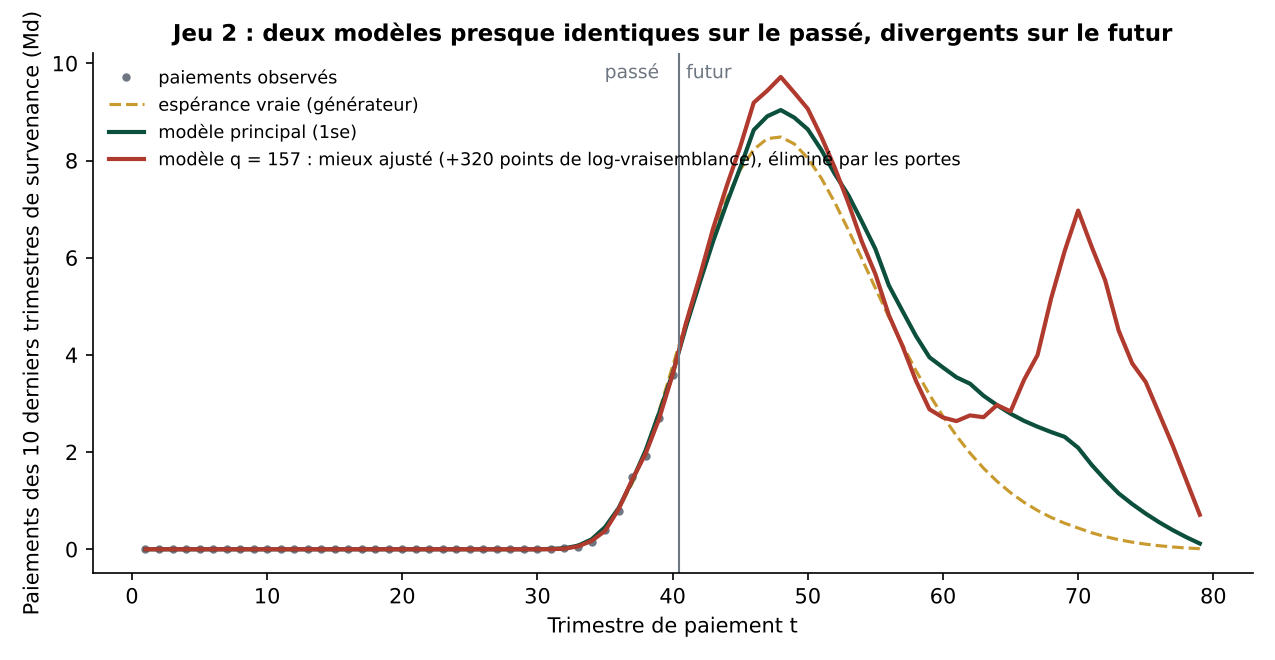

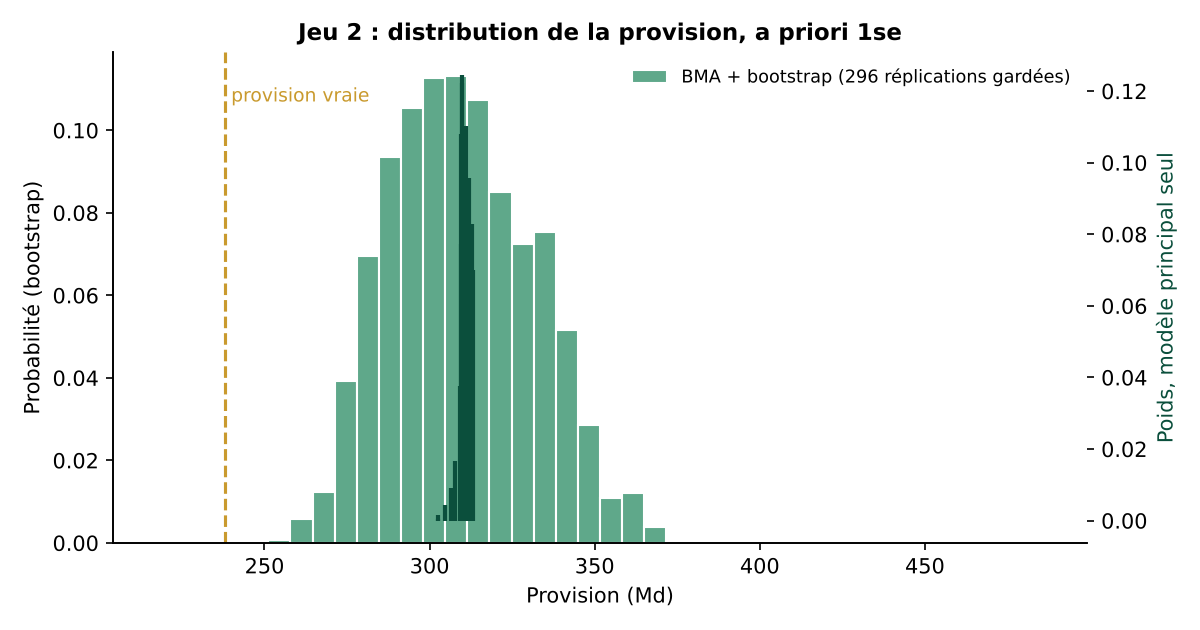

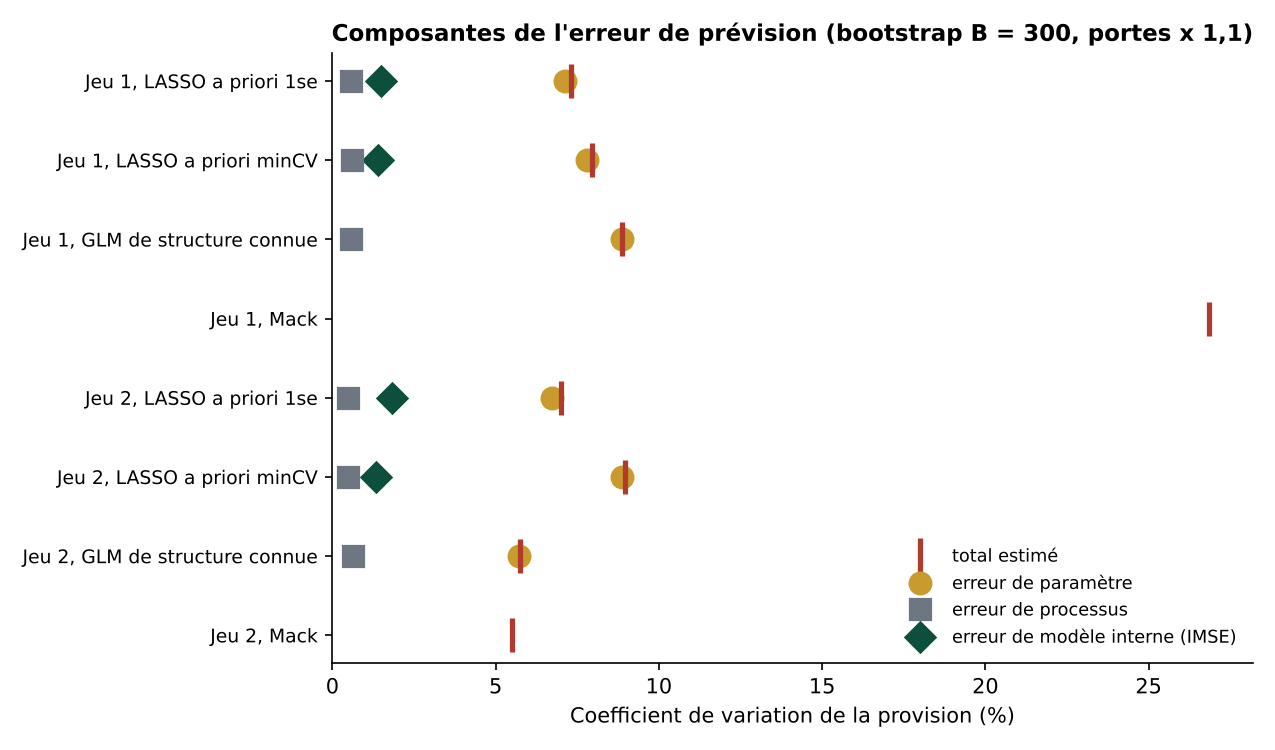

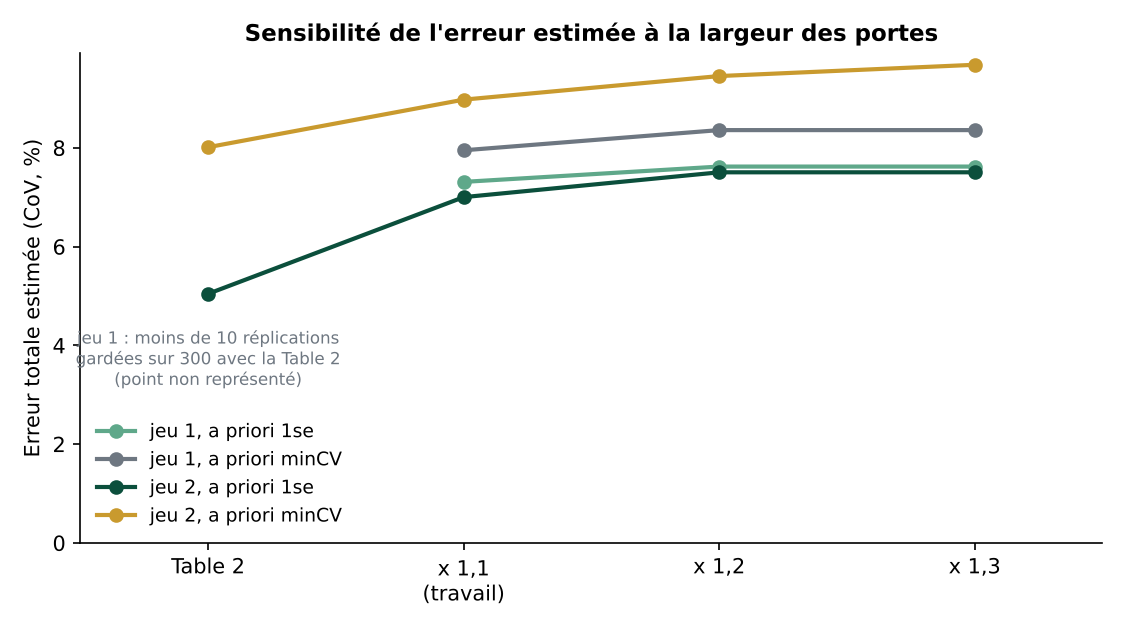

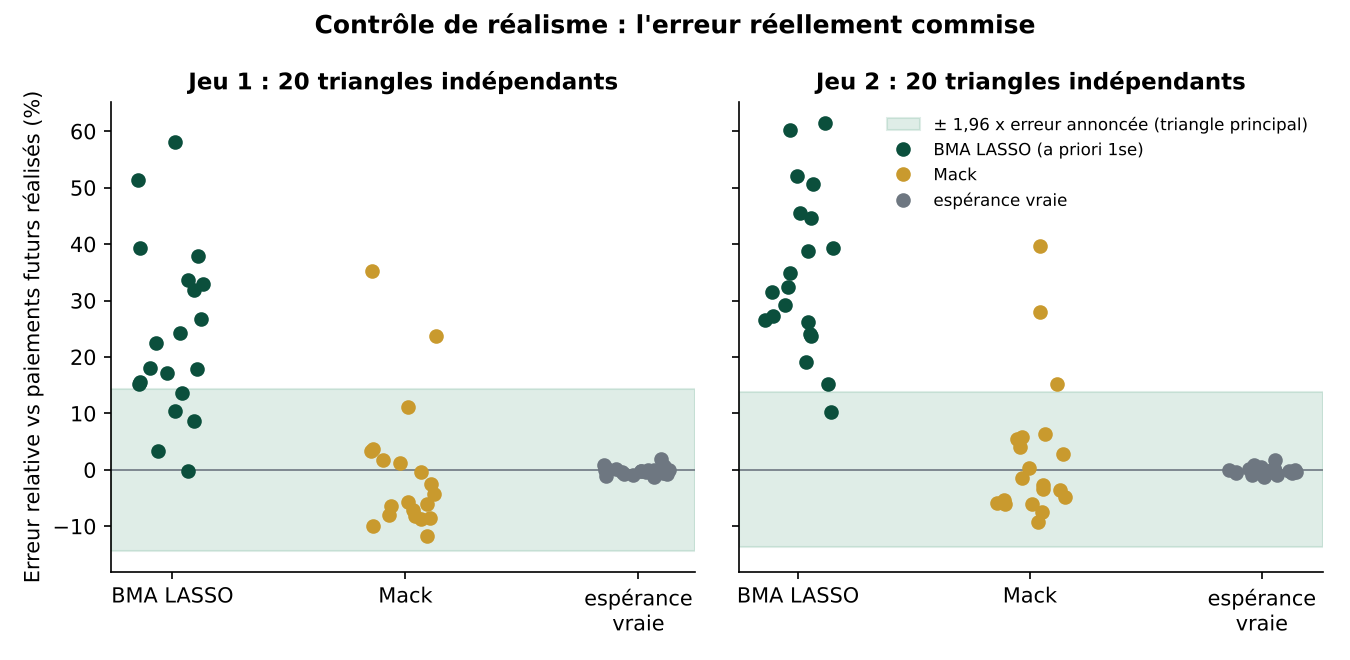

In [13]:
for f in ('fig_jeu2_bon_ajustement_mauvaise_prevision', 'fig_jeu2_distribution_provision', 'fig_decomposition_erreur',
          'fig_sensibilite_portes', 'fig_realisme'):
    display(Image(f'results/figures/{f}.png'))